# Hierarchical Clustering - Experiment 2

This experiment uses Age, Annual Income, and Spending Score. These features are standardized before clustering so that no feature dominates because of its scale.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

plt.style.use("default")

## 1. Load and Select the Data

In [2]:
# Load the dataset using a path relative to the repository
df = pd.read_csv("Mall_Customers.csv")

features = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]
X = df[features]

print("Dataset shape:", df.shape)
print("Missing values:")
print(X.isnull().sum())
X.head()

Dataset shape: (200, 5)
Missing values:
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


## 2. Standardize the Three Features

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)
X_scaled_df.describe().round(3)

,Age,Annual Income (k$),Spending Score (1-100)
count,200.000,200.000,200.000
mean,-0.000,-0.000,-0.000
std,1.003,1.003,1.003
min,-1.496,-1.739,-1.910
25%,-0.725,-0.728,-0.600
50%,-0.205,0.036,-0.008
75%,0.728,0.666,0.885
max,2.236,2.918,1.894


## 3. Dendrogram

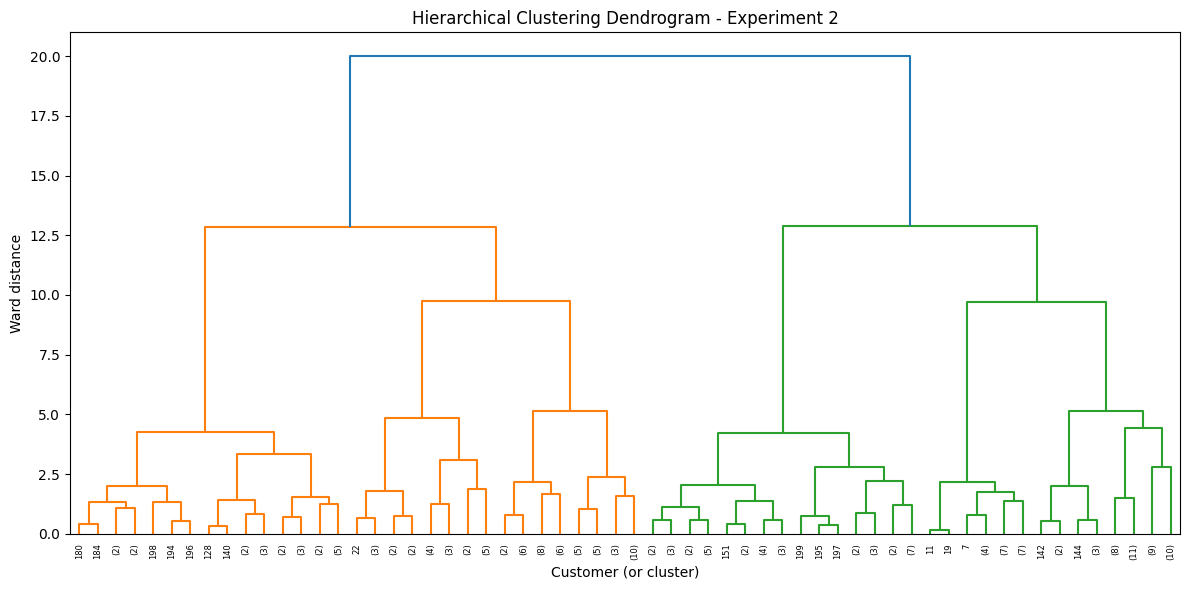

In [4]:
# Ward linkage minimizes within-cluster variance
linked = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 6))
dendrogram(linked, truncate_mode="level", p=5)
plt.title("Hierarchical Clustering Dendrogram - Experiment 2")
plt.xlabel("Customer (or cluster)")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()

## 4. Choose the Number of Clusters

Agglomerative clustering is tested with 2 through 10 clusters. The cluster count with the highest silhouette score is selected because it gives the best balance of cluster separation and cohesion in this experiment.

In [5]:
silhouette_scores = {}

for k in range(2, 11):
    model = AgglomerativeClustering(n_clusters=k, linkage="ward")
    labels = model.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

score_table = pd.DataFrame({
    "Number of clusters": list(silhouette_scores.keys()),
    "Silhouette score": list(silhouette_scores.values())
}).set_index("Number of clusters")

score_table.round(4)

,Silhouette score
Number of clusters,
2,0.3180
3,0.3215
4,0.3615
5,0.3900
6,0.4201
7,0.3983
8,0.3665
9,0.3754
10,0.3809


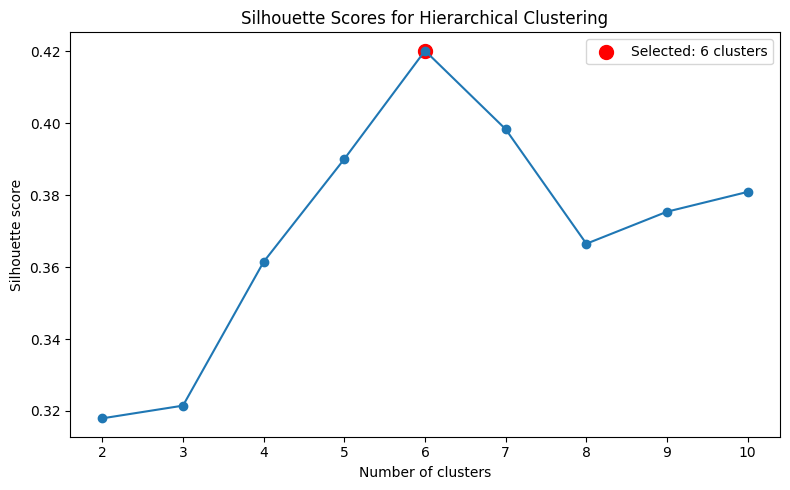

Selected cluster count: 6
Highest silhouette score: 0.4201


In [6]:
selected_k = max(silhouette_scores, key=silhouette_scores.get)

plt.figure(figsize=(8, 5))
plt.plot(list(silhouette_scores.keys()), list(silhouette_scores.values()), marker="o")
plt.scatter(selected_k, silhouette_scores[selected_k], color="red", s=100,
            label=f"Selected: {selected_k} clusters")
plt.title("Silhouette Scores for Hierarchical Clustering")
plt.xlabel("Number of clusters")
plt.ylabel("Silhouette score")
plt.xticks(range(2, 11))
plt.legend()
plt.tight_layout()
plt.show()

print(f"Selected cluster count: {selected_k}")
print(f"Highest silhouette score: {silhouette_scores[selected_k]:.4f}")

**Choice explanation:** The notebook automatically selects the cluster count that maximizes the silhouette score. This balances within-cluster similarity and separation between clusters.

## 5. Apply the Selected Hierarchical Clustering

In [7]:
hierarchical = AgglomerativeClustering(n_clusters=selected_k, linkage="ward")
df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

print("Cluster sizes:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

Cluster sizes:
Hierarchical_Cluster
0    45
1    45
2    39
3    28
4    22
5    21
Name: count, dtype: int64


## 6. Visualize the Three-Feature Clusters

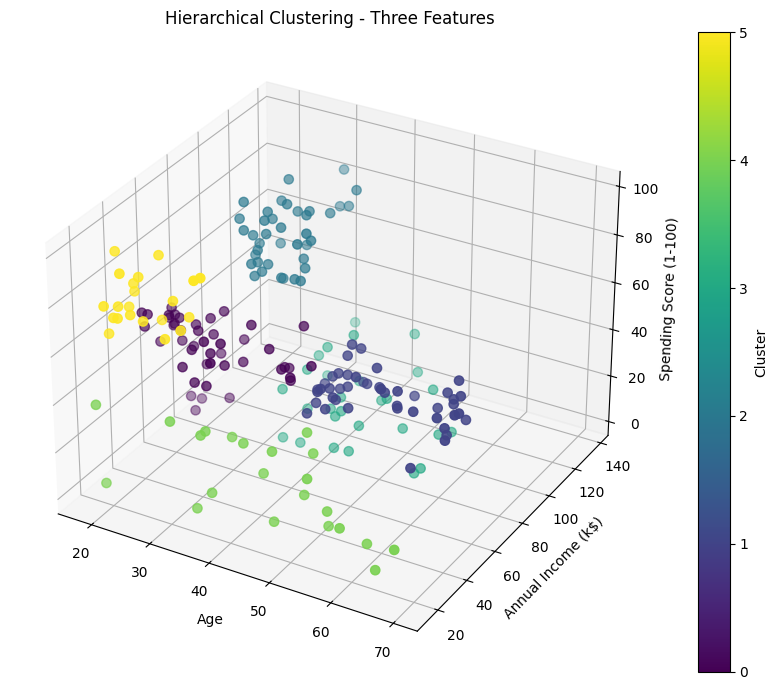

In [8]:
# Three-dimensional cluster plot using the original feature values
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
scatter = ax.scatter(
    df["Age"],
    df["Annual Income (k$)"],
    df["Spending Score (1-100)"],
    c=df["Hierarchical_Cluster"],
    cmap="viridis",
    s=45
)
ax.set_title("Hierarchical Clustering - Three Features")
ax.set_xlabel("Age")
ax.set_ylabel("Annual Income (k$)")
ax.set_zlabel("Spending Score (1-100)")
fig.colorbar(scatter, ax=ax, label="Cluster")
plt.tight_layout()
plt.show()

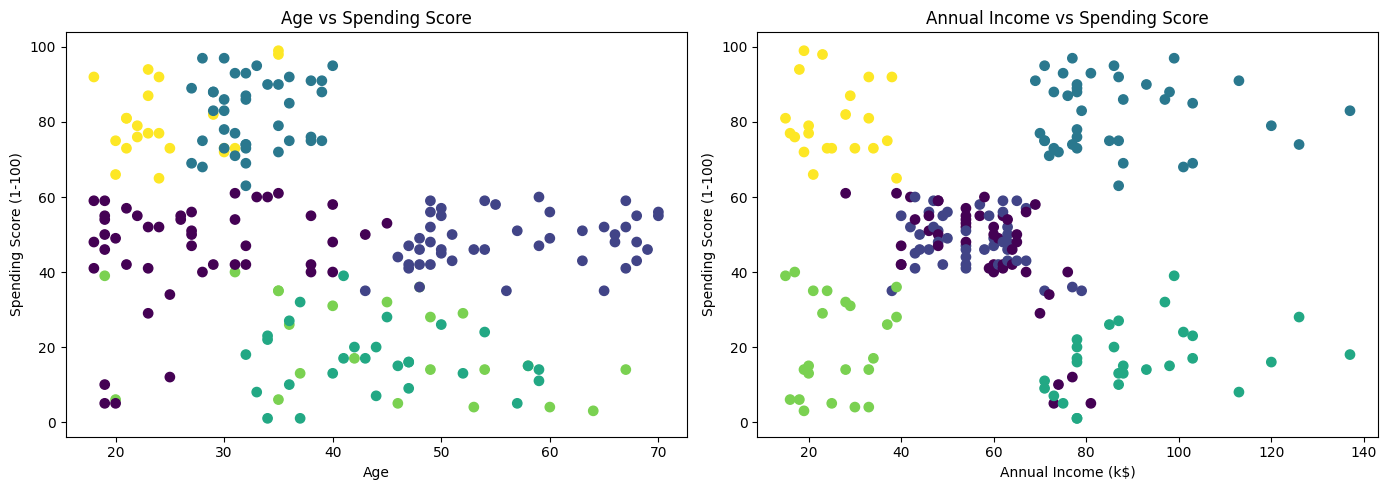

In [9]:
# Pairwise 2D views of the same clusters
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    df["Age"], df["Spending Score (1-100)"],
    c=df["Hierarchical_Cluster"], cmap="viridis", s=45
)
axes[0].set_title("Age vs Spending Score")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Spending Score (1-100)")

axes[1].scatter(
    df["Annual Income (k$)"], df["Spending Score (1-100)"],
    c=df["Hierarchical_Cluster"], cmap="viridis", s=45
)
axes[1].set_title("Annual Income vs Spending Score")
axes[1].set_xlabel("Annual Income (k$)")
axes[1].set_ylabel("Spending Score (1-100)")

plt.tight_layout()
plt.show()

## 7. Final Silhouette Score

In [10]:
final_score = silhouette_score(X_scaled, df["Hierarchical_Cluster"])
print(f"Number of clusters: {selected_k}")
print(f"Final silhouette score: {final_score:.4f}")

Number of clusters: 6
Final silhouette score: 0.4201


## 8. Cluster Summary

In [11]:
cluster_table = df.groupby("Hierarchical_Cluster").agg(
    Number_of_Customers=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Annual_Income=("Annual Income (k$)", "mean"),
    Average_Spending_Score=("Spending Score (1-100)", "mean")
).round(2)

cluster_table

,Number_of_Customers,Average_Age,Average_Annual_Income,Average_Spending_Score
Hierarchical_Cluster,,,,
0,45,27.38,57.51,45.84
1,45,56.40,55.29,48.36
2,39,32.69,86.54,82.13
3,28,43.89,91.29,16.68
4,22,44.32,25.77,20.27
5,21,24.81,25.62,80.24


## 9. Save Customer Cluster Assignments

In [12]:
df.to_csv("hierarchical_exp2_result.csv", index=False)
print("Hierarchical Experiment 2 results saved to hierarchical_exp2_result.csv")

Hierarchical Experiment 2 results saved to hierarchical_exp2_result.csv
